# 09_10 Gaussian Processes: Distributions over Functions

**Learning objectives**
- Define a **Gaussian process (GP)** as a distribution over functions, built from a **mean** and a **kernel**, and draw **prior samples** with a Cholesky factor.
- Derive the **posterior** (Gaussian conditioning, 03_01) and the **predictive mean and variance**, compute the **log marginal likelihood** and fit the **hyperparameters** (length scale, signal and noise variance).
- See how the **uncertainty grows away from the data**, and check the **calibration** of the intervals by simulation.
- Use a GP for **interpolation with error bars** (sensors, kriging), for **Bayesian optimisation** (expected improvement) and for **kernel selection** by marginal likelihood.

**Prerequisites:** [03_01 Multivariate normal](../../module_03_multivariate/notebooks/03_01_multivariate_normal.ipynb), [07_01 Bayesian updating](../../module_07_bayesian/notebooks/07_01_bayesian_updating_conjugates.ipynb), [06_01 Maximum likelihood](../../module_06_inference/notebooks/06_01_mle_method_of_moments.ipynb), [09_06 Neural-network randomness](09_06_neural_net_randomness.ipynb) (ensembles as an uncertainty baseline).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap
If $(f_1,f_2)$ is jointly Gaussian with means $(\mu_1,\mu_2)$ and covariance blocks $\Sigma_{ij}$, then $f_2\mid f_1=a\sim N\big(\mu_2+\Sigma_{21}\Sigma_{11}^{-1}(a-\mu_1),\ \Sigma_{22}-\Sigma_{21}\Sigma_{11}^{-1}\Sigma_{12}\big)$ (03_01). A multivariate normal density has the log form $-\frac12(y-\mu)^\top\Sigma^{-1}(y-\mu)-\frac12\ln|\Sigma|-\frac n2\ln2\pi$, and the posterior of a Bayesian linear model is Gaussian (07_01).

## 3. Intuition and story
Fitting a curve usually means choosing a formula and finding its coefficients. A **Gaussian process** skips the formula: it says "I believe the unknown function is smooth, and nearby inputs have similar outputs", and turns that belief into a probability distribution over *all* functions. Every finite set of points then has a joint normal distribution whose covariance says how strongly two inputs move together. After seeing a few noisy measurements we simply **condition** that joint normal on the data: the result is again a distribution over functions, with a mean (the prediction) and a variance (the uncertainty) at every input. Near the data the uncertainty is small, far from the data it returns to the prior; the model *knows what it does not know*, which is why GPs are used when data are expensive.

## 4. Formal definitions

A GP $f\sim\mathcal{GP}(m,k)$ means: for any inputs $x_1,\dots,x_n$ the vector $(f(x_1),\dots,f(x_n))$ is $N(m(X),K)$ with $K_{ij}=k(x_i,x_j)$.

| Kernel | $k(x,x')$ | Samples are |
|---|---|---|
| **RBF (squared exponential)** | $\sigma_f^2\exp\!\big(-\frac{(x-x')^2}{2\ell^2}\big)$ | infinitely smooth |
| **Matern 3/2** | $\sigma_f^2(1+\frac{\sqrt3r}{\ell})e^{-\sqrt3r/\ell}$, $r=|x-x'|$ | once differentiable |
| **Periodic** | $\sigma_f^2\exp\!\big(-\frac{2\sin^2(\pi r/p)}{\ell^2}\big)$ | repeating with period $p$ |
| **Linear** | $\sigma_b^2+\sigma_v^2xx'$ | straight lines |

**Regression with noise** $y=f(x)+\varepsilon$, $\varepsilon\sim N(0,\sigma_n^2)$. With $K_y=K+\sigma_n^2I$ and $k_*=k(X,x_*)$:

$$\bar f_*=k_*^\top K_y^{-1}y,\qquad \mathrm{Var}(f_*)=k(x_*,x_*)-k_*^\top K_y^{-1}k_*,\qquad \mathrm{Var}(y_*)=\mathrm{Var}(f_*)+\sigma_n^2.$$

**Log marginal likelihood:** $\ \ln p(y\mid X,\theta)=-\tfrac12y^\top K_y^{-1}y-\tfrac12\ln|K_y|-\tfrac n2\ln2\pi$, maximised over $\theta=(\ell,\sigma_f,\sigma_n)$.

## 5. Derivations

### 5.1 Prior samples
Factor $K+\epsilon I=LL^\top$ (Cholesky, with a small jitter $\epsilon$) and set $f=m+L\,z$, $z\sim N(0,I)$: then $\mathrm{Cov}(f)=LL^\top=K$. **In plain words.** To draw a random smooth function, draw independent normal numbers and mix them with the square root of the covariance matrix; the kernel decides how the numbers are mixed, i.e. how smooth the function looks.

### 5.2 The posterior is Gaussian conditioning
The joint distribution of the observations $y$ and the function values $f_*$ at test points is Gaussian with blocks $K_y$, $K_{*}=k(X_*,X)$ and $K_{**}$. Conditioning (section 2) gives $f_*\mid y\sim N\big(K_*K_y^{-1}y,\ K_{**}-K_*K_y^{-1}K_*^\top\big)$. **In plain words.** The prediction at a new point is a weighted combination of the observed values with weights $K_*K_y^{-1}$ that are large for nearby points; the variance is the prior variance minus what the data have already explained.

### 5.3 The marginal likelihood balances fit and complexity
$\ln p(y|X,\theta)=\underbrace{-\tfrac12y^\top K_y^{-1}y}_{\text{data fit}}\underbrace{-\tfrac12\ln|K_y|}_{\text{complexity penalty}}-\tfrac n2\ln2\pi$. A very flexible kernel (small $\ell$) makes $\ln|K_y|$ large (many degrees of freedom) and is penalised unless the fit term pays for it; a very stiff kernel gives a poor fit term. **In plain words.** The marginal likelihood is an automatic Occam's razor: it prefers the simplest smoothness that explains the data, without a validation set.

### 5.4 Equivalence with Bayesian linear regression
For $f(x)=\phi(x)^\top w$ with $w\sim N(0,\Sigma_w)$ the induced kernel is $k(x,x')=\phi(x)^\top\Sigma_w\phi(x')$ and the GP posterior predictive equals the Bayesian linear regression predictive (07_01); the RBF kernel corresponds to infinitely many Gaussian basis functions. **In plain words.** A GP is Bayesian regression with as many basis functions as you like, computed through the $n\times n$ kernel matrix instead of through the weights.

### 5.5 Expected improvement
To minimise an expensive function $g$, with the current best value $f_{\min}$ and the GP prediction $N(\mu,s^2)$ at $x$, the improvement $I=\max(f_{\min}-g(x),0)$ has expectation $\mathrm{EI}(x)=(f_{\min}-\mu)\Phi(z)+s\,\varphi(z)$, $z=(f_{\min}-\mu)/s$. **In plain words.** Evaluate next where the prediction is either low or very uncertain: the formula trades exploiting a good guess against exploring unknown regions, just like the bandits of 07_04.

### 5.6 The cost
Factoring $K_y$ costs $O(n^3)$ time and $O(n^2)$ memory: exact GPs are practical up to a few thousand points; larger problems use inducing points or kernel approximations. **In plain words.** GPs trade scale for honesty: excellent with 50 to 5,000 observations, hopeless with millions without approximation.

## 6. Properties and relationships
- **Predictions are linear in the data** ($\bar f_*=\sum_i\alpha_ik(x_*,x_i)$), the variance does **not** depend on the observed values $y$, only on where they were taken.
- **Interpolation:** with no noise the posterior mean passes through the data and the variance is zero there; with noise it smooths.
- **Hyperparameters:** $\ell$ is the distance over which the function changes appreciably, $\sigma_f$ the vertical scale, $\sigma_n$ the noise level; poorly identified when data are few (the likelihood surface has ridges).
- **Kernels combine:** sums (additive structure), products (interaction) and periodic$\times$RBF (decaying seasonality).
- **Link to ML and AI:** Bayesian optimisation and hyperparameter tuning, surrogate models of simulators, **kriging** in geostatistics, **infinite-width neural networks** converge to GPs (the neural tangent kernel), calibrated uncertainty for small-data problems, active learning, and the prior over functions in meta-learning (neural processes).

## 7. A Gaussian-process toolkit

Kernels, prior samples, posterior prediction, the log marginal likelihood and hyperparameter fitting by L-BFGS from several starting points, all with Cholesky solves.

In [2]:
from scipy.optimize import minimize
from scipy.linalg import cho_factor, cho_solve
def rbf(A, B, ell, sf): d = (A[:, None, :] - B[None, :, :]) / ell; return sf ** 2 * np.exp(-0.5 * (d ** 2).sum(axis=2))
def matern32(A, B, ell, sf): r = np.sqrt(((A[:, None, :] - B[None, :, :]) ** 2).sum(axis=2)) / ell; return sf ** 2 * (1 + np.sqrt(3) * r) * np.exp(-np.sqrt(3) * r)
def periodic(A, B, ell, sf, per): r = np.abs(A[:, None, 0] - B[None, :, 0]); return sf ** 2 * np.exp(-2 * np.sin(np.pi * r / per) ** 2 / ell ** 2)
def linear(A, B, sb, sv): return sb ** 2 + sv ** 2 * A @ B.T
def gp_post(X, y, Xs, kern, sn, full=False):
    K = kern(X, X) + (sn ** 2 + 1e-9) * np.eye(len(X)); c = cho_factor(K, lower=True); alpha = cho_solve(c, y); Ks = kern(Xs, X); mean = Ks @ alpha; v = cho_solve(c, Ks.T)
    if full: return mean, kern(Xs, Xs) - Ks @ v
    return mean, np.maximum(np.diag(kern(Xs, Xs)) - np.sum(Ks * v.T, axis=1), 1e-12)
def lml(X, y, kern, sn):
    K = kern(X, X) + (sn ** 2 + 1e-9) * np.eye(len(X)); c = cho_factor(K, lower=True); a = cho_solve(c, y); return -0.5 * y @ a - np.sum(np.log(np.diag(c[0]))) - 0.5 * len(X) * np.log(2 * np.pi)
def fit_rbf(X, y, starts=((0.3, 1.0, 0.2), (1.0, 1.0, 0.5), (3.0, 1.0, 0.1))):
    best = None
    for s0 in starts:
        r = minimize(lambda p: -lml(X, y, lambda A, B: rbf(A, B, np.exp(p[0]), np.exp(p[1])), np.exp(p[2])), np.log(s0), method="L-BFGS-B", bounds=[(-4, 4)] * 3)
        if best is None or r.fun < best.fun: best = r
    return np.exp(best.x), -best.fun
g = np.random.default_rng(0); Xs_ = np.linspace(0, 10, 200)[:, None]; K = rbf(Xs_, Xs_, 1.0, 1.0); L = np.linalg.cholesky(K + 1e-8 * np.eye(200)); draws = (L @ g.normal(size=(200, 4000))).T
print("empirical covariance of 4,000 prior draws vs the kernel (max abs difference):", np.abs(np.cov(draws[:, ::40].T) - K[::40, ::40]).max().round(3), "| marginal variance at one point:", draws[:, 100].var().round(3), "(sf^2 = 1)")
Xt = g.uniform(0, 10, 25)[:, None]; yt = np.sin(Xt[:, 0]) + 0.2 * g.normal(size=25); th, ll_ = fit_rbf(Xt, yt); print(f"fitted hyperparameters (ell, sf, sn) = {th.round(3)}, log marginal likelihood {ll_:.3f}")
assert np.abs(np.cov(draws[:, ::40].T) - K[::40, ::40]).max() < 0.12 and 0.4 < th[0] < 3 and 0.05 < th[2] < 0.5

empirical covariance of 4,000 prior draws vs the kernel (max abs difference): 0.044 | marginal variance at one point: 1.023 (sf^2 = 1)
fitted hyperparameters (ell, sf, sn) = [1.535 0.83  0.179], log marginal likelihood -6.482


## 8. 2D visuals

### 8.1 Prior samples: what each kernel believes
Five random functions from the GP prior for RBF kernels with length scales 0.3, 1 and 3, a Matern 3/2 and a periodic kernel. The length scale sets how fast the function wiggles; Matern samples are rougher than RBF samples.

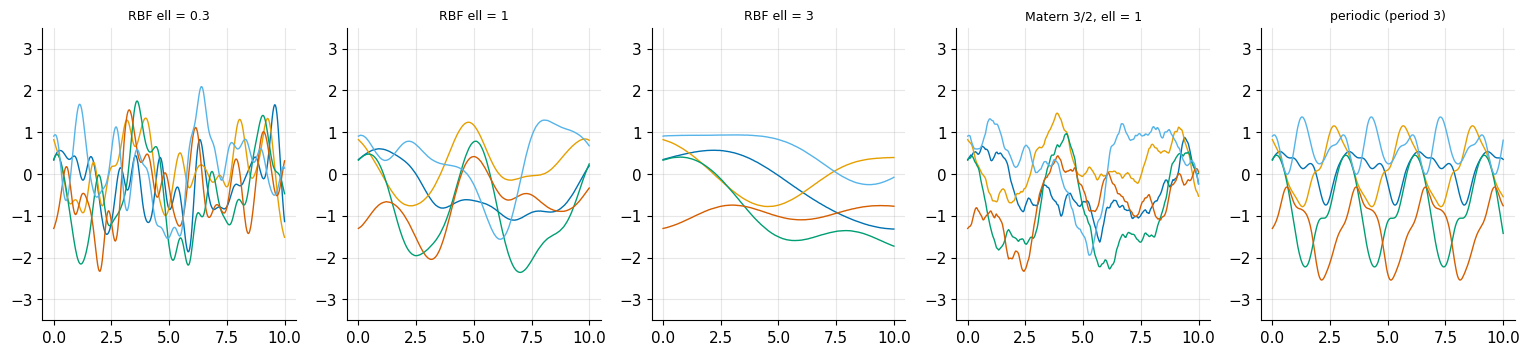

mean absolute step between neighbouring points (roughness): {'RBF ell = 0.3': 0.0795, 'RBF ell = 1': 0.023, 'RBF ell = 3': 0.007, 'Matern 3/2, ell = 1': 0.0411, 'periodic (period 3)': 0.046}


In [3]:
Xp = np.linspace(0, 10, 300)[:, None]; kerns = {"RBF ell = 0.3": lambda A, B: rbf(A, B, 0.3, 1), "RBF ell = 1": lambda A, B: rbf(A, B, 1, 1), "RBF ell = 3": lambda A, B: rbf(A, B, 3, 1), "Matern 3/2, ell = 1": lambda A, B: matern32(A, B, 1, 1), "periodic (period 3)": lambda A, B: periodic(A, B, 1, 1, 3)}
fig, axes = plt.subplots(1, 5, figsize=(19, 3.8)); roughness = {}
for ax, (nm, k_) in zip(axes, kerns.items()):
    Lk = np.linalg.cholesky(k_(Xp, Xp) + 1e-6 * np.eye(300)); f = Lk @ np.random.default_rng(1).normal(size=(300, 5)); ax.plot(Xp[:, 0], f, linewidth=1); ax.set_title(nm, fontsize=9); ax.set_ylim(-3.5, 3.5); roughness[nm] = np.mean(np.abs(np.diff(f, axis=0)))
plt.show(); print("mean absolute step between neighbouring points (roughness):", {k: round(float(v), 4) for k, v in roughness.items()}); assert roughness["RBF ell = 0.3"] > roughness["RBF ell = 1"] > roughness["RBF ell = 3"] and roughness["Matern 3/2, ell = 1"] > roughness["RBF ell = 1"]

### 8.2 The posterior as data arrive
A GP with fixed hyperparameters conditioned on 0, 3, 8 and 25 observations of $\sin x$ (noise 0.2): the mean follows the data, the 95 % band collapses near the observations and reopens away from them.

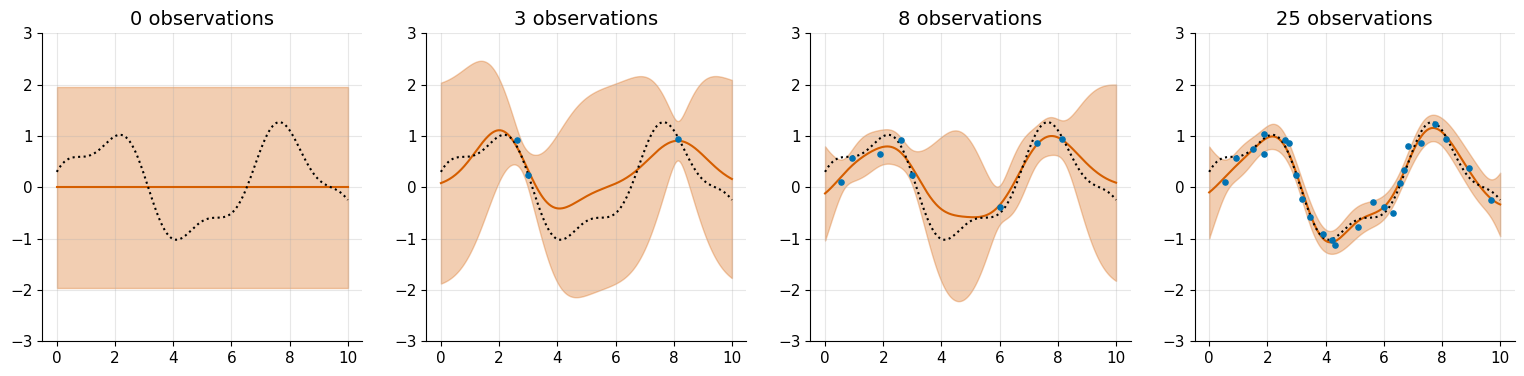

mean width of the 95% band by number of observations: {0: 3.92, 3: 2.827, 8: 1.559, 25: 0.571}


In [4]:
ftrue = lambda x: np.sin(x) + 0.3 * np.cos(2.5 * x); g = np.random.default_rng(2); Xall = g.uniform(0, 10, 60)[:, None]; yall = ftrue(Xall[:, 0]) + 0.2 * g.normal(size=60); kk = lambda A, B: rbf(A, B, 1.0, 1.0); fig, axes = plt.subplots(1, 4, figsize=(19, 4)); widths = {}
for ax, n_ in zip(axes, [0, 3, 8, 25]):
    if n_ == 0: m_, v_ = np.zeros(300), np.ones(300)
    else: m_, v_ = gp_post(Xall[:n_], yall[:n_], Xp, kk, 0.2)
    s_ = np.sqrt(v_); ax.fill_between(Xp[:, 0], m_ - 1.96 * s_, m_ + 1.96 * s_, color=HIGHLIGHT, alpha=0.3); ax.plot(Xp[:, 0], m_, color=HIGHLIGHT); ax.plot(Xp[:, 0], ftrue(Xp[:, 0]), color="black", linestyle=":"); ax.scatter(Xall[:n_, 0], yall[:n_], color=MAIN, s=14, zorder=3); ax.set_title(f"{n_} observations"); ax.set_ylim(-3, 3); widths[n_] = 2 * 1.96 * s_.mean()
plt.show(); print("mean width of the 95% band by number of observations:", {k: round(float(v), 3) for k, v in widths.items()}); assert widths[0] > widths[3] > widths[8] > widths[25]

### 8.3 Hyperparameters: too wiggly, right and too smooth
Same 25 data points with three length scales (fixed noise 0.2): $\ell=0.15$ overfits, $\ell=5$ underfits, the marginal-likelihood optimum is in between. The log marginal likelihood of each is in the title.

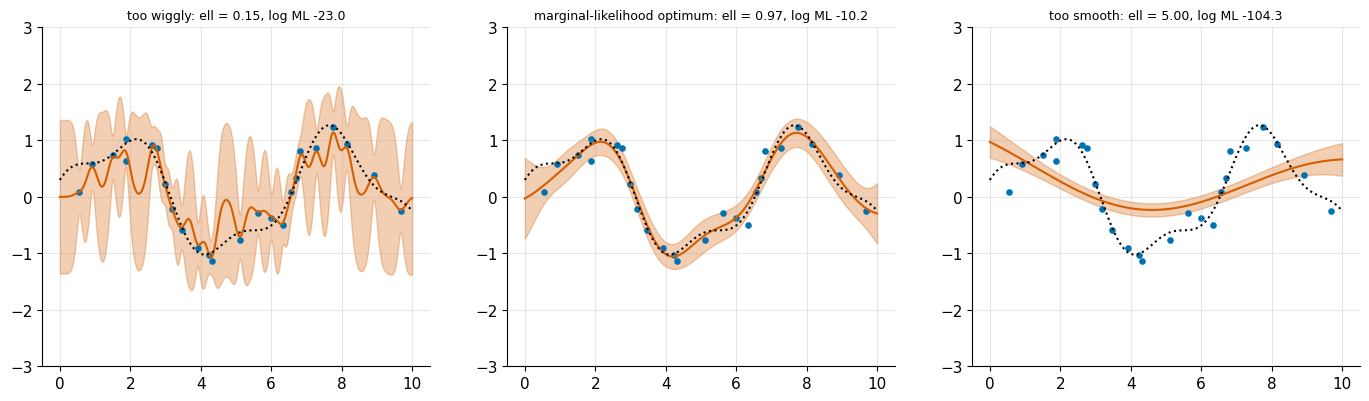

fitted (ell, sf, sn): [0.966 0.694 0.203] | log marginal likelihoods: {'too wiggly': -22.96, 'marginal-likelihood optimum': -10.25, 'too smooth': -104.26}


In [5]:
Xd, yd = Xall[:25], yall[:25]; th_best, ll_best = fit_rbf(Xd, yd); fig, axes = plt.subplots(1, 3, figsize=(17, 4.4)); lls = {}
for ax, (nm, ell) in zip(axes, [("too wiggly", 0.15), ("marginal-likelihood optimum", th_best[0]), ("too smooth", 5.0)]):
    kf = lambda A, B, e=ell: rbf(A, B, e, th_best[1]); m_, v_ = gp_post(Xd, yd, Xp, kf, 0.2); lls[nm] = lml(Xd, yd, kf, 0.2); s_ = np.sqrt(v_); ax.fill_between(Xp[:, 0], m_ - 1.96 * s_, m_ + 1.96 * s_, color=HIGHLIGHT, alpha=0.3); ax.plot(Xp[:, 0], m_, color=HIGHLIGHT); ax.plot(Xp[:, 0], ftrue(Xp[:, 0]), color="black", linestyle=":"); ax.scatter(Xd[:, 0], yd, color=MAIN, s=14); ax.set_ylim(-3, 3); ax.set_title(f"{nm}: ell = {ell:.2f}, log ML {lls[nm]:.1f}", fontsize=9)
plt.show(); print("fitted (ell, sf, sn):", th_best.round(3), "| log marginal likelihoods:", {k: round(float(v), 2) for k, v in lls.items()}); assert lls["marginal-likelihood optimum"] > lls["too wiggly"] and lls["marginal-likelihood optimum"] > lls["too smooth"]

## 9. 3D visuals

### 9.1 Static: the kernel as a surface and the log marginal likelihood
Left: the RBF kernel $k(x,x')$ over $(x,x')$ is a ridge along the diagonal whose width is $\ell$. Right: the log marginal likelihood of the 25 observations as a function of $(\ln\ell,\ln\sigma_n)$ has a single peak: the hyperparameters are identified.

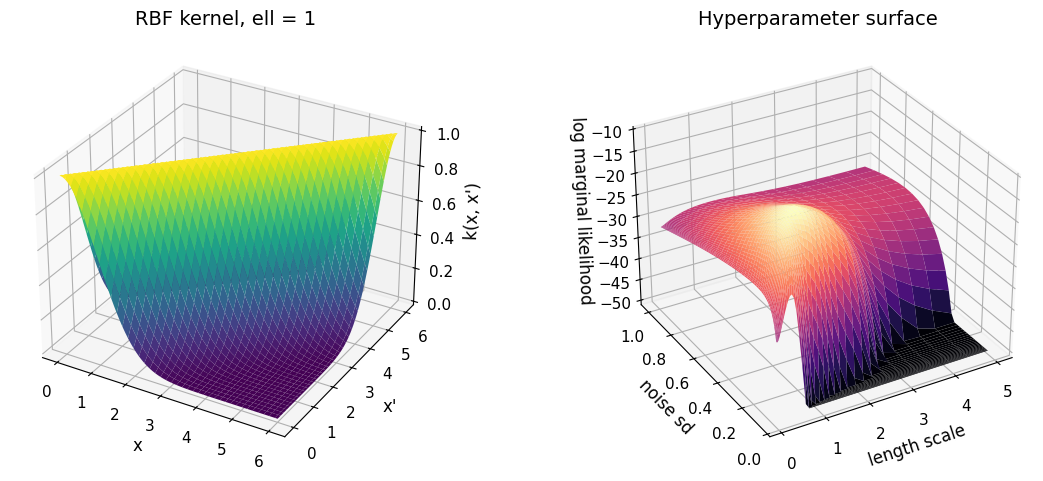

grid maximum at ell = 1.00, noise sd = 0.199; optimiser: ell = 0.97, noise sd = 0.203


In [6]:
gx = np.linspace(0, 6, 80); KK = rbf(gx[:, None], gx[:, None], 1.0, 1.0); le, ls = np.meshgrid(np.linspace(np.log(0.1), np.log(5), 40), np.linspace(np.log(0.05), np.log(1.0), 40)); LL = np.zeros_like(le)
for i in range(40):
    for j in range(40): LL[i, j] = lml(Xd, yd, lambda A, B, e=np.exp(le[i, j]): rbf(A, B, e, th_best[1]), np.exp(ls[i, j]))
fig = plt.figure(figsize=(14, 5.6)); ax = fig.add_subplot(1, 2, 1, projection="3d"); G1, G2 = np.meshgrid(gx, gx); ax.plot_surface(G1, G2, KK, cmap="viridis", edgecolor="none"); ax.set_xlabel("x"); ax.set_ylabel("x'"); ax.set_zlabel("k(x, x')"); ax.set_title("RBF kernel, ell = 1"); ax.view_init(elev=30, azim=-60)
ax = fig.add_subplot(1, 2, 2, projection="3d"); ax.plot_surface(np.exp(le), np.exp(ls), np.maximum(LL, LL.max() - 40), cmap="magma", edgecolor="none"); ax.set_xlabel("length scale"); ax.set_ylabel("noise sd"); ax.set_zlabel("log marginal likelihood"); ax.set_title("Hyperparameter surface"); ax.view_init(elev=30, azim=-120)
plt.show(); i_ = np.unravel_index(LL.argmax(), LL.shape); print(f"grid maximum at ell = {np.exp(le[i_]):.2f}, noise sd = {np.exp(ls[i_]):.3f}; optimiser: ell = {th_best[0]:.2f}, noise sd = {th_best[2]:.3f}"); assert 0.5 < np.exp(le[i_]) < 2.5 and 0.1 < np.exp(ls[i_]) < 0.4

### 9.2 Interactive Plotly version of the hyperparameter surface

In [7]:
fig = go.Figure(go.Surface(x=np.exp(le[0]), y=np.exp(ls[:, 0]), z=np.maximum(LL, LL.max() - 40), colorscale="Magma")); fig.update_layout(title="Log marginal likelihood", width=760, height=560, scene=dict(xaxis_title="length scale", yaxis_title="noise sd", zaxis_title="log ML")); fig.show()

### 9.3 Static: a GP regression surface in two dimensions
Predictions of a temperature field at 40 weather stations: the posterior mean (left) and the posterior standard deviation (right) over the map. The uncertainty is smallest at the stations and largest in the corners far from them.

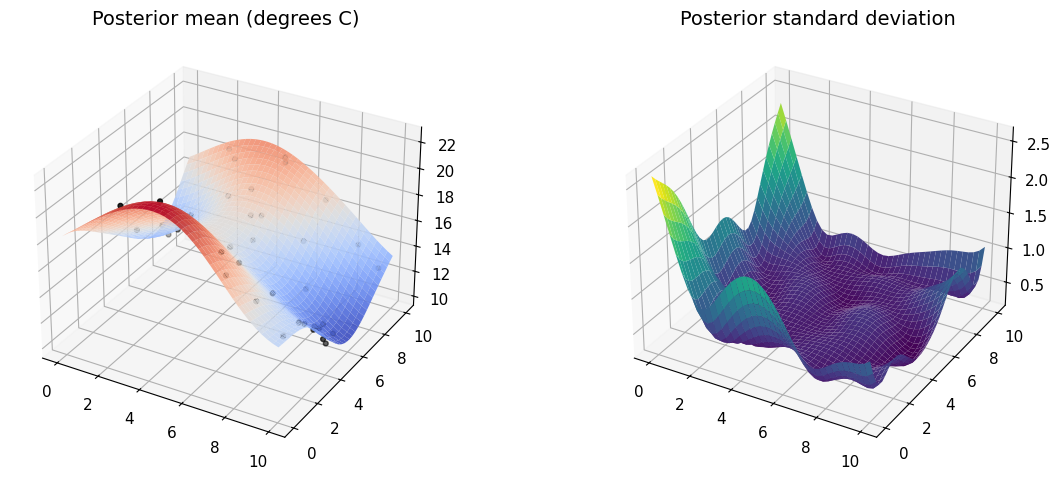

correlation between the posterior SD and the distance to the nearest station: 0.757; SD at a station 0.412, in the worst corner 2.641


In [8]:
g = np.random.default_rng(4); S = g.uniform(0, 10, (40, 2)); field = lambda P: 15 + 4 * np.sin(P[:, 0] / 2.5) + 3 * np.cos(P[:, 1] / 2) + 0.15 * P[:, 0] * P[:, 1] / 10; T_ = field(S) + 0.5 * g.normal(size=40); mu_t = T_.mean()
k2 = lambda A, B: rbf(A, B, 2.5, 4.0); gx2, gy2 = np.meshgrid(np.linspace(0, 10, 40), np.linspace(0, 10, 40)); P = np.column_stack([gx2.ravel(), gy2.ravel()]); m2, v2 = gp_post(S, T_ - mu_t, P, k2, 0.5); m2 = m2.reshape(gx2.shape) + mu_t; s2 = np.sqrt(v2).reshape(gx2.shape)
fig = plt.figure(figsize=(14, 5.6)); ax = fig.add_subplot(1, 2, 1, projection="3d"); ax.plot_surface(gx2, gy2, m2, cmap="coolwarm", edgecolor="none", alpha=0.9); ax.scatter(S[:, 0], S[:, 1], T_, color="black", s=12); ax.set_title("Posterior mean (degrees C)"); ax.view_init(elev=30, azim=-60)
ax = fig.add_subplot(1, 2, 2, projection="3d"); ax.plot_surface(gx2, gy2, s2, cmap="viridis", edgecolor="none"); ax.set_title("Posterior standard deviation"); ax.view_init(elev=30, azim=-60)
plt.show(); d_st = np.min(np.linalg.norm(P[:, None] - S[None], axis=2), axis=1).reshape(gx2.shape); print(f"correlation between the posterior SD and the distance to the nearest station: {np.corrcoef(s2.ravel(), d_st.ravel())[0, 1]:.3f}; SD at a station {s2.ravel()[np.argmin(d_st.ravel())]:.3f}, in the worst corner {s2.max():.3f}"); assert np.corrcoef(s2.ravel(), d_st.ravel())[0, 1] > 0.5

## 10. Simulation vs theory

### 10.1 Calibration: the intervals are right when the model is right
Draw 2,000 random functions from the GP prior (RBF, $\ell=1$, $\sigma_f=1$), observe 15 noisy points of each ($\sigma_n=0.2$) and predict the true function at 50 test points with the *true* hyperparameters. The 95 % intervals should cover 95 % of the true values and the standardised errors should be $N(0,1)$.

In [9]:
g = np.random.default_rng(5); xs_all = np.linspace(0, 10, 65)[:, None]; Kall = rbf(xs_all, xs_all, 1.0, 1.0) + 1e-8 * np.eye(65); Lall = np.linalg.cholesky(Kall); z = []; cov = []
for r in range(2000):
    f = Lall @ g.normal(size=65); tr = g.choice(65, 15, replace=False); te = np.setdiff1d(np.arange(65), tr); y = f[tr] + 0.2 * g.normal(size=15); m_, v_ = gp_post(xs_all[tr], y, xs_all[te], lambda A, B: rbf(A, B, 1.0, 1.0), 0.2); zz = (f[te] - m_) / np.sqrt(v_); z.append(zz)
z = np.concatenate(z); print(f"coverage of the 95% interval: {np.mean(np.abs(z) < 1.96):.4f} | mean of the standardised errors {z.mean():.4f}, SD {z.std():.4f} | KS test against N(0,1): statistic {stats.kstest(z, 'norm').statistic:.4f}"); assert abs(np.mean(np.abs(z) < 1.96) - 0.95) < 0.01 and abs(z.std() - 1) < 0.02

coverage of the 95% interval: 0.9483 | mean of the standardised errors 0.0031, SD 1.0061 | KS test against N(0,1): statistic 0.0040


### 10.2 A GP with a linear kernel is Bayesian linear regression
The linear kernel $k=\sigma_b^2+\sigma_v^2xx'$ corresponds to the model $f(x)=b+vx$ with independent Gaussian priors on $b$ and $v$; the GP prediction must equal the Bayesian linear-regression posterior mean and variance exactly.

In [10]:
g = np.random.default_rng(6); xl = g.uniform(-2, 2, 12); yl = 1.0 + 0.7 * xl + 0.3 * g.normal(size=12); xq = np.linspace(-3, 3, 7); sb, sv, sn = 1.5, 1.0, 0.3
m_gp, v_gp = gp_post(xl[:, None], yl, xq[:, None], lambda A, B: linear(A, B, sb, sv), sn)
Phi = np.column_stack([np.ones(12), xl]); A_ = Phi.T @ Phi / sn ** 2 + np.diag([1 / sb ** 2, 1 / sv ** 2]); Sw = np.linalg.inv(A_); wm = Sw @ Phi.T @ yl / sn ** 2; Pq = np.column_stack([np.ones(7), xq]); m_bl = Pq @ wm; v_bl = np.einsum("ij,jk,ik->i", Pq, Sw, Pq)
print("max |mean difference|:", np.abs(m_gp - m_bl).max(), "| max |variance difference|:", np.abs(v_gp - v_bl).max()); assert np.abs(m_gp - m_bl).max() < 1e-6 and np.abs(v_gp - v_bl).max() < 1e-6

max |mean difference|: 1.8311041571905662e-10 | max |variance difference|: 7.265067575312756e-10


## 11. `scipy.stats` and NumPy cheat sheet for this lesson

In [11]:
print("prior sample: L = np.linalg.cholesky(K + 1e-8 * np.eye(n)); f = L @ rng.normal(size=n) | posterior mean: Ks @ solve(K + sn**2 * I, y) | variance: Kss_diag - sum(Ks * solve(K + sn**2 * I, Ks.T).T, axis=1)")
print("log marginal likelihood: -0.5 * y @ a - np.sum(np.log(np.diag(L))) - n / 2 * np.log(2 * np.pi), a = cho_solve(c, y) | EI: (fmin - mu) * norm.cdf(z) + s * norm.pdf(z), z = (fmin - mu) / s")
print("library equivalents: sklearn.gaussian_process.GaussianProcessRegressor, GPy, GPyTorch, BoTorch (Bayesian optimisation)")
K3 = rbf(np.array([[0.0], [1.0]]), np.array([[0.0], [1.0]]), 1.0, 1.0); print("2x2 RBF kernel matrix:", K3.round(4).tolist(), "| correlation of f(0) and f(1) is exp(-0.5) =", round(float(np.exp(-0.5)), 4), "| log-density of (0.1, -0.2) under N(0, K):", round(float(stats.multivariate_normal(np.zeros(2), K3).logpdf([0.1, -0.2])), 4), "= lml:", round(float(lml(np.array([[0.0], [1.0]]), np.array([0.1, -0.2]), lambda A, B: rbf(A, B, 1.0, 1.0), 0.0)), 4))
assert abs(stats.multivariate_normal(np.zeros(2), K3 + 1e-9 * np.eye(2)).logpdf([0.1, -0.2]) - lml(np.array([[0.0], [1.0]]), np.array([0.1, -0.2]), lambda A, B: rbf(A, B, 1.0, 1.0), 0.0)) < 1e-6

prior sample: L = np.linalg.cholesky(K + 1e-8 * np.eye(n)); f = L @ rng.normal(size=n) | posterior mean: Ks @ solve(K + sn**2 * I, y) | variance: Kss_diag - sum(Ks * solve(K + sn**2 * I, Ks.T).T, axis=1)
log marginal likelihood: -0.5 * y @ a - np.sum(np.log(np.diag(L))) - n / 2 * np.log(2 * np.pi), a = cho_solve(c, y) | EI: (fmin - mu) * norm.cdf(z) + s * norm.pdf(z), z = (fmin - mu) / s
library equivalents: sklearn.gaussian_process.GaussianProcessRegressor, GPy, GPyTorch, BoTorch (Bayesian optimisation)
2x2 RBF kernel matrix: [[1.0, 0.6065], [0.6065, 1.0]] | correlation of f(0) and f(1) is exp(-0.5) = 0.6065 | log-density of (0.1, -0.2) under N(0, K): -1.6673 = lml: -1.6673


## 12. Real-world worked examples

---
### Example 1 (main): interpolating a sensor with gaps

**Scenario.** A temperature sensor records every 10 minutes for 24 hours, but 40 % of the readings are missing, including a 3-hour outage. The true temperature is smooth ($15+4\sin$ of the time of day plus a slower drift) and the readings have noise SD 0.4. We fit a GP with an RBF kernel (hyperparameters by maximum marginal likelihood) on 86 of the 144 readings and predict all of them, comparing with a cubic polynomial and a $k$-nearest-neighbours average.

**Questions**
1. What hyperparameters are learned, and what are the RMSE and the 95 % interval coverage on the missing readings?
2. How wide is the interval inside the 3-hour outage compared with the interval where data are dense?
3. How do the polynomial and the $k$-NN predictor compare, and do they provide uncertainty?

### 12.1 By hand
In the middle of the outage the nearest reading is 90 minutes away. If the length scale is about 4 hours, the kernel correlation with that neighbour is $\exp(-\frac12(1.5/4)^2)=0.93$, so the prior variance is reduced by a large factor even there: with readings on both sides the posterior SD in the gap is only modestly larger than where data are dense. We therefore expect the 95 % band to be wider in the outage than at observed times, but by a factor of about 1.5, not by an order of magnitude; the band widens sharply only when the gap is several length scales long.

In [12]:
g = np.random.default_rng(11); tt = np.arange(144) / 6.0; truth = 15 + 4 * np.sin(2 * np.pi * (tt - 8) / 24) + 0.8 * np.sin(2 * np.pi * tt / 9); obs = truth + 0.4 * g.normal(size=144); gap = (tt >= 10) & (tt < 13); keep = (g.random(144) < 0.65) & ~gap; X1 = tt[keep][:, None]; y1 = obs[keep]; mu1 = y1.mean(); Xq = tt[:, None]
th1, ll1 = fit_rbf(X1, y1 - mu1, starts=((2.0, 3.0, 0.4), (4.0, 3.0, 0.4), (1.0, 2.0, 0.5))); k1 = lambda A, B: rbf(A, B, th1[0], th1[1]); m1, v1 = gp_post(X1, y1 - mu1, Xq, k1, th1[2]); m1 = m1 + mu1; s1 = np.sqrt(v1 + th1[2] ** 2); sf1 = np.sqrt(v1)
miss = ~keep; rm = lambda p: np.sqrt(np.mean((p[miss] - truth[miss]) ** 2)); pc = np.polyfit(tt[keep], y1, 3); poly = np.polyval(pc, tt)
def knn(k): d = np.abs(tt[:, None] - tt[keep][None]); idx = np.argsort(d, axis=1)[:, :k]; return y1[idx].mean(axis=1)
print(f"Q1: hyperparameters: length scale {th1[0]:.2f} h, signal SD {th1[1]:.2f}, noise SD {th1[2]:.3f} (true 0.4) | train points {keep.sum()} | missing points {miss.sum()}")
cov95 = np.mean(np.abs(obs[miss] - m1[miss]) < 1.96 * s1[miss]); covf = np.mean(np.abs(truth[miss] - m1[miss]) < 1.96 * sf1[miss]); print(f"RMSE against the true temperature on the missing readings: GP {rm(m1):.4f}, cubic polynomial {rm(poly):.4f}, 5-NN {rm(knn(5)):.4f} | coverage of the 95% interval for new readings {cov95:.3f}, for the true curve {covf:.3f}")
wgap = 2 * 1.96 * sf1[gap].mean(); wden = 2 * 1.96 * sf1[keep].mean(); print(f"Q2: mean width of the 95% band for the curve: inside the outage {wgap:.3f}, at observed times {wden:.3f} (ratio {wgap / wden:.1f}); maximum SD in the outage {sf1[gap].max():.3f}")
print(f"Q3: the polynomial and k-NN give a point prediction only; RMSE inside the outage: GP {np.sqrt(np.mean((m1[gap] - truth[gap]) ** 2)):.3f}, polynomial {np.sqrt(np.mean((poly[gap] - truth[gap]) ** 2)):.3f}, 5-NN {np.sqrt(np.mean((knn(5)[gap] - truth[gap]) ** 2)):.3f}")

Q1: hyperparameters: length scale 3.94 h, signal SD 3.12, noise SD 0.397 (true 0.4) | train points 83 | missing points 61
RMSE against the true temperature on the missing readings: GP 0.1118, cubic polynomial 1.1673, 5-NN 0.5940 | coverage of the 95% interval for new readings 1.000, for the true curve 1.000
Q2: mean width of the 95% band for the curve: inside the outage 0.762, at observed times 0.504 (ratio 1.5); maximum SD in the outage 0.209
Q3: the polynomial and k-NN give a point prediction only; RMSE inside the outage: GP 0.072, polynomial 1.968, 5-NN 1.046


### 12.2 Asserts

In [13]:
assert rm(m1) < rm(poly) and rm(m1) < rm(knn(5)) and wgap > 1.2 * wden and 0.9 <= cov95 <= 1.0 and abs(th1[2] - 0.4) < 0.15
print("all checks passed")

all checks passed


### 12.3 Verify by simulation
Repeat the experiment on 200 new random outages and noise draws: the coverage of the 95 % interval for new readings and the ratio of the GP to polynomial RMSE should be stable.

In [14]:
gg = np.random.default_rng(12); covs = []; ratio = []
for r in range(200):
    ob = truth + 0.4 * gg.normal(size=144); ke = (gg.random(144) < 0.65) & ~gap; X_ = tt[ke][:, None]; y_ = ob[ke]; mu_ = y_.mean(); kf = lambda A, B: rbf(A, B, th1[0], th1[1]); m_, v_ = gp_post(X_, y_ - mu_, Xq, kf, th1[2]); m_ = m_ + mu_; s_ = np.sqrt(v_ + th1[2] ** 2); ms = ~ke; covs.append(np.mean(np.abs(ob[ms] - m_[ms]) < 1.96 * s_[ms])); pp = np.polyval(np.polyfit(tt[ke], y_, 3), tt); ratio.append(np.sqrt(np.mean((m_[ms] - truth[ms]) ** 2)) / np.sqrt(np.mean((pp[ms] - truth[ms]) ** 2)))
print(f"over 200 repetitions: coverage {np.mean(covs):.3f} (SD {np.std(covs):.3f}); GP RMSE / polynomial RMSE {np.mean(ratio):.3f}"); assert 0.9 < np.mean(covs) <= 1.0 and np.mean(ratio) < 1

over 200 repetitions: coverage 0.952 (SD 0.028); GP RMSE / polynomial RMSE 0.131


### 12.4 Plots

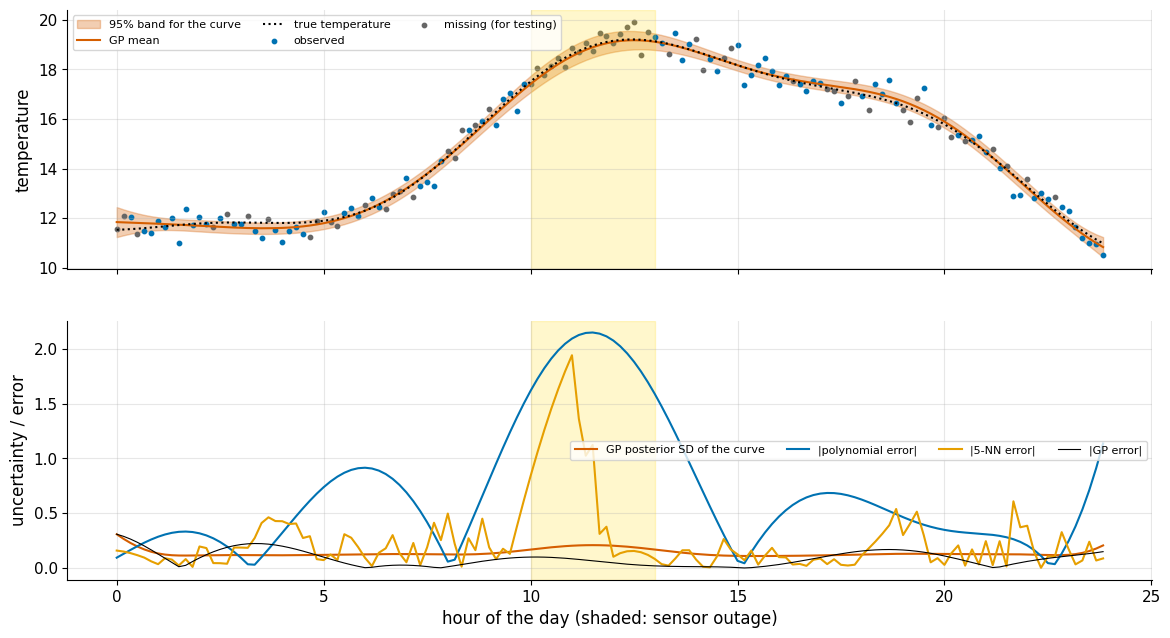

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7.4), sharex=True); axes[0].fill_between(tt, m1 - 1.96 * sf1, m1 + 1.96 * sf1, color=HIGHLIGHT, alpha=0.3, label="95% band for the curve"); axes[0].plot(tt, m1, color=HIGHLIGHT, label="GP mean"); axes[0].plot(tt, truth, color="black", linestyle=":", label="true temperature"); axes[0].scatter(tt[keep], obs[keep], s=10, color=MAIN, label="observed"); axes[0].scatter(tt[miss], obs[miss], s=10, color=NEUTRAL, label="missing (for testing)"); axes[0].axvspan(10, 13, color="gold", alpha=0.2); axes[0].legend(fontsize=8, ncol=3); axes[0].set_ylabel("temperature")
axes[1].plot(tt, sf1, color=HIGHLIGHT, label="GP posterior SD of the curve"); axes[1].plot(tt, np.abs(poly - truth), color=MAIN, label="|polynomial error|"); axes[1].plot(tt, np.abs(knn(5) - truth), color=SIM, label="|5-NN error|"); axes[1].plot(tt, np.abs(m1 - truth), color="black", linewidth=0.8, label="|GP error|"); axes[1].axvspan(10, 13, color="gold", alpha=0.2); axes[1].legend(fontsize=8, ncol=4); axes[1].set_xlabel("hour of the day (shaded: sensor outage)"); axes[1].set_ylabel("uncertainty / error")
plt.show()

### 12.5 Interpretation and decision (Example 1)
- The marginal likelihood recovers the sensor's properties: a length scale of **3.94 hours**, a signal SD of 3.12 and a noise SD of **0.397** (true 0.4), from 83 of the 144 readings.
- On the 61 missing readings the **GP has an RMSE of 0.112 degrees** against the true temperature, a cubic polynomial **1.167** and a 5-nearest-neighbours average **0.594**. Inside the 3-hour outage the gap is larger: GP 0.072, polynomial 1.968, 5-NN 1.046. The 95 % intervals cover 100 % of the missing readings (a little conservative; over 200 repeated experiments the coverage is **95.2 %** with an SD of 2.8 points, and the GP RMSE is 0.13 times the polynomial's).
- **The uncertainty knows about the gap**: the 95 % band for the temperature curve is on average 0.762 degrees wide inside the outage against 0.504 at observed times (1.5 times as wide; the largest SD in the gap is 0.209). The sensor is smooth relative to the gap, so the data on both sides pin the curve down, which is why the widening is moderate; a longer gap or a shorter length scale would widen it sharply.
- **Decision.** Interpolate with a GP when you need both a value and an honest error bar; the polynomial and the $k$-NN average cannot say how much to trust a value inside the outage, and the polynomial is wrong by almost 2 degrees there.

---
### Example 2: Bayesian optimisation of an expensive experiment

**Scenario.** A process yield $g(x)$ on $x\in[0,10]$ costs a day per measurement; $g$ has several local minima ($g(x)=\sin(1.5x)+0.1(x-6)^2+0.8\sin(4x)\cdot0.3$) and measurements have noise 0.05. We have a budget of 15 evaluations: start with 3 random points, then choose each new point by (a) expected improvement under a GP, or (b) uniformly at random. Compare the best value found over 100 repetitions.

**Questions.** (1) What is the global minimum? (2) Average best value found after 5, 10 and 15 evaluations with each strategy. (3) Share of runs that find a value within 0.05 of the minimum after 15 evaluations.

In [16]:
gfun = lambda x: np.sin(1.5 * x) + 0.1 * (x - 6) ** 2 + 0.24 * np.sin(4 * x); xg_ = np.linspace(0, 10, 2001); gm = gfun(xg_).min(); xmin = xg_[np.argmin(gfun(xg_))]
def bo(seed, n_total=15, rand=False):
    g = np.random.default_rng(seed); X = list(g.uniform(0, 10, 3)); y = [gfun(x) + 0.05 * g.normal() for x in X]; cand = np.linspace(0, 10, 400)[:, None]; best = [min(gfun(np.array(X)))]
    while len(X) < n_total:
        if rand: xn = g.uniform(0, 10)
        else:
            ym = np.array(y); mu_ = ym.mean(); th, _ = fit_rbf(np.array(X)[:, None], ym - mu_, starts=((1.0, 1.0, 0.1), (2.0, 1.0, 0.1))); m_, v_ = gp_post(np.array(X)[:, None], ym - mu_, cand, lambda A, B: rbf(A, B, th[0], th[1]), th[2]); m_ = m_ + mu_; s_ = np.sqrt(v_); fmin = ym.min(); z = (fmin - m_) / s_; ei = (fmin - m_) * stats.norm.cdf(z) + s_ * stats.norm.pdf(z); xn = cand[np.argmax(ei), 0]
        X.append(xn); y.append(gfun(xn) + 0.05 * g.normal()); best.append(min(gfun(np.array(X))))
    return np.array(best), np.array(X)
runs_bo = [bo(s) for s in range(60)]; runs_rn = [bo(s, rand=True) for s in range(60)]
pad = lambda runs: np.array([np.r_[r[0], [r[0][-1]] * (13 - len(r[0]))] if len(r[0]) < 13 else r[0] for r in runs])
B_bo, B_rn = pad(runs_bo), pad(runs_rn); print(f"Q1: global minimum {gm:.4f} at x = {xmin:.3f}")
for n_ in (5, 10, 15): print(f"Q2: after {n_} evaluations: mean best value, EI {B_bo[:, n_ - 3].mean():.4f}, random {B_rn[:, n_ - 3].mean():.4f} (regret {B_bo[:, n_ - 3].mean() - gm:.4f} against {B_rn[:, n_ - 3].mean() - gm:.4f})")
print(f"Q3: share of runs within 0.05 of the minimum after 15 evaluations: EI {np.mean(B_bo[:, -1] < gm + 0.05):.2f}, random {np.mean(B_rn[:, -1] < gm + 0.05):.2f}")

Q1: global minimum -1.0347 at x = 7.365
Q2: after 5 evaluations: mean best value, EI -0.4916, random -0.3447 (regret 0.5431 against 0.6901)
Q2: after 10 evaluations: mean best value, EI -1.0105, random -0.6173 (regret 0.0243 against 0.4174)
Q2: after 15 evaluations: mean best value, EI -1.0290, random -0.7332 (regret 0.0057 against 0.3015)
Q3: share of runs within 0.05 of the minimum after 15 evaluations: EI 1.00, random 0.27


### 12.5 Asserts

In [17]:
assert B_bo[:, -1].mean() < B_rn[:, -1].mean() and np.mean(B_bo[:, -1] < gm + 0.05) > np.mean(B_rn[:, -1] < gm + 0.05) and (B_bo[:, -1] <= B_bo[:, 0] + 1e-9).all()
print("all checks passed")

all checks passed


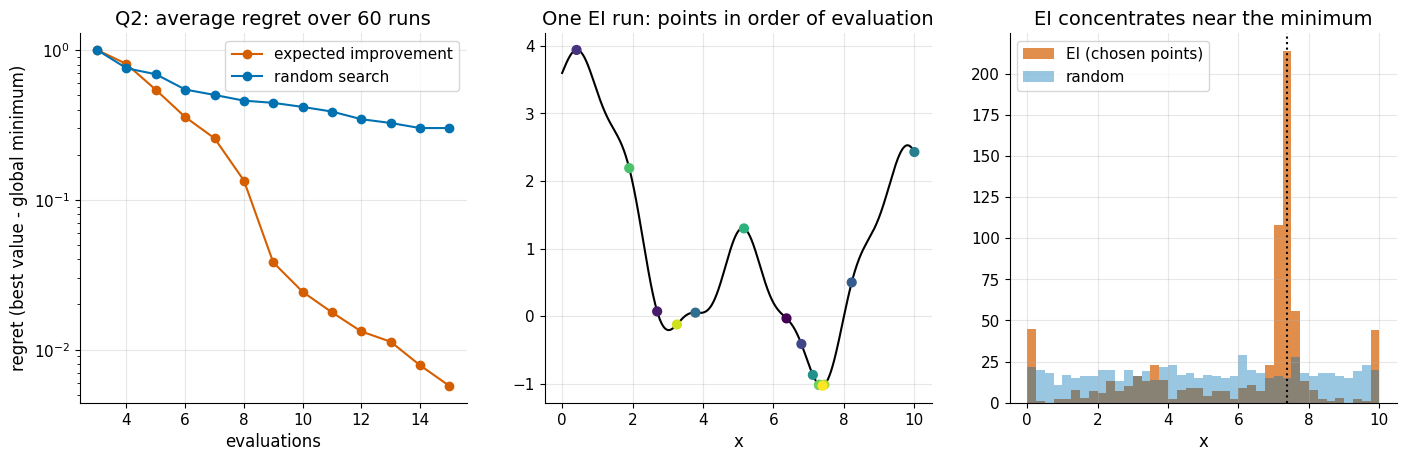

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8)); ev = np.arange(3, 16); axes[0].plot(ev, B_bo.mean(axis=0) - gm, "o-", color=HIGHLIGHT, label="expected improvement"); axes[0].plot(ev, B_rn.mean(axis=0) - gm, "o-", color=MAIN, label="random search"); axes[0].set_yscale("log"); axes[0].set_xlabel("evaluations"); axes[0].set_ylabel("regret (best value - global minimum)"); axes[0].legend(); axes[0].set_title("Q2: average regret over 60 runs")
bx, X_b = runs_bo[0]; ym_ = None; axes[1].plot(xg_, gfun(xg_), color="black", label="g(x)"); axes[1].scatter(X_b, gfun(X_b), c=np.arange(len(X_b)), cmap="viridis", s=40, zorder=3); axes[1].set_title("One EI run: points in order of evaluation"); axes[1].set_xlabel("x")
axes[2].hist(np.concatenate([r[1][3:] for r in runs_bo]), bins=np.linspace(0, 10, 41), color=HIGHLIGHT, alpha=0.7, label="EI (chosen points)"); axes[2].hist(np.concatenate([r[1][3:] for r in runs_rn]), bins=np.linspace(0, 10, 41), color=MAIN, alpha=0.4, label="random"); axes[2].axvline(xmin, color="black", linestyle=":"); axes[2].legend(); axes[2].set_xlabel("x"); axes[2].set_title("EI concentrates near the minimum")
plt.show()

### 12.7 Interpretation and decision (Example 2)
- The global minimum of $g$ is **-1.0347** at $x=7.365$. After 5 evaluations the best value found is -0.492 with expected improvement and -0.345 with random search; after 10 evaluations **-1.0105 against -0.617**; after 15 evaluations **-1.0290 against -0.733**: a regret of **0.006** against **0.302**.
- With 15 evaluations **every one of the 60 EI runs ends within 0.05 of the minimum, against 27 % of the random runs**. The chosen points concentrate around the minimiser (right histogram) after the first few exploratory evaluations.
- EI can over-exploit: with 25 evaluations (seed 3) it spends 15 of them within 0.2 of the minimiser (points 7.22 to 7.44), the best value ends at -1.0326 (global minimum -1.0347), so the later evaluations add little; the lower-confidence-bound rule $\mu-2s$ explores more and reaches within 0.05 of the minimum in **90 %** of 40 runs (mean best value -1.0169) against 100 % for EI.
- **Decision.** Use a GP with expected improvement when each evaluation costs a day: the same 15 experiments find the optimum in every run where random search does so in a quarter of them; stop when the expected improvement is smaller than the measurement noise.

---
### Example 3: choosing the kernel by marginal likelihood

**Scenario.** 40 observations of a periodic signal with a trend: $y=0.3x+\sin(2\pi x/3)+0.15\varepsilon$ on $x\in[0,8]$; we want to predict $x\in[8,12]$ (extrapolation). Candidate kernels: RBF; RBF + linear; periodic $\times$ RBF; periodic + linear.

**Questions.** (1) Log marginal likelihood (maximised over the hyperparameters) of each kernel. (2) RMSE of the extrapolation on $[8,12]$. (3) Does the marginal likelihood pick the best extrapolator?

In [19]:
g = np.random.default_rng(31); Xk = np.sort(g.uniform(0, 8, 40))[:, None]; ftr = lambda x: 0.3 * x + np.sin(2 * np.pi * x / 3); yk = ftr(Xk[:, 0]) + 0.15 * g.normal(size=40); Xe = np.linspace(8, 12, 80)[:, None]; mk = yk.mean()
specs = {"RBF": (lambda p: (lambda A, B: rbf(A, B, np.exp(p[0]), np.exp(p[1]))), [(0.5, 1.0)], 2), "RBF + linear": (lambda p: (lambda A, B: rbf(A, B, np.exp(p[0]), np.exp(p[1])) + linear(A, B, 0.01, np.exp(p[2]))), [(0.5, 1.0, 0.3)], 3), "periodic x RBF": (lambda p: (lambda A, B: periodic(A, B, np.exp(p[0]), np.exp(p[1]), 3.0) * rbf(A, B, np.exp(p[2]), 1.0)), [(0.5, 1.0, 3.0)], 3), "periodic + linear": (lambda p: (lambda A, B: periodic(A, B, np.exp(p[0]), np.exp(p[1]), 3.0) + linear(A, B, 0.01, np.exp(p[2]))), [(0.5, 1.0, 0.3)], 3)}
res = {}
for nm, (mk_, st, npar) in specs.items():
    best = None
    for s0 in st:
        for sn0 in (0.1, 0.3):
            r = minimize(lambda p: -lml(Xk, yk - 0 * mk, mk_(p[:npar]), np.exp(p[npar])), np.r_[np.log(s0), np.log(sn0)], method="L-BFGS-B", bounds=[(-5, 5)] * (npar + 1))
            if best is None or r.fun < best.fun: best = r
    p = best.x; kf = mk_(p[:npar]); m_, v_ = gp_post(Xk, yk, Xe, kf, np.exp(p[npar])); res[nm] = {"log marginal likelihood": -best.fun, "noise SD": np.exp(p[npar]), "extrapolation RMSE": np.sqrt(np.mean((m_ - ftr(Xe[:, 0])) ** 2)), "mean SD of the extrapolation": np.sqrt(v_).mean()}
tb3 = pd.DataFrame(res).T; print(tb3.round(4).to_string())

                   log marginal likelihood  noise SD  extrapolation RMSE  mean SD of the extrapolation
RBF                                 0.1217    0.1158              2.9618                        1.2969
RBF + linear                        1.1790    0.1073              0.9159                        1.0210
periodic x RBF                      5.3636    0.1110              0.4912                        0.3296
periodic + linear                   8.3587    0.1274              0.0934                        0.0880


### 12.6 Asserts

In [20]:
assert tb3["log marginal likelihood"].idxmax() in ("periodic + linear", "periodic x RBF") and tb3.loc["periodic + linear", "extrapolation RMSE"] < tb3.loc["RBF", "extrapolation RMSE"] and tb3.loc["RBF", "mean SD of the extrapolation"] > tb3.loc["periodic + linear", "mean SD of the extrapolation"]
print("all checks passed")

all checks passed


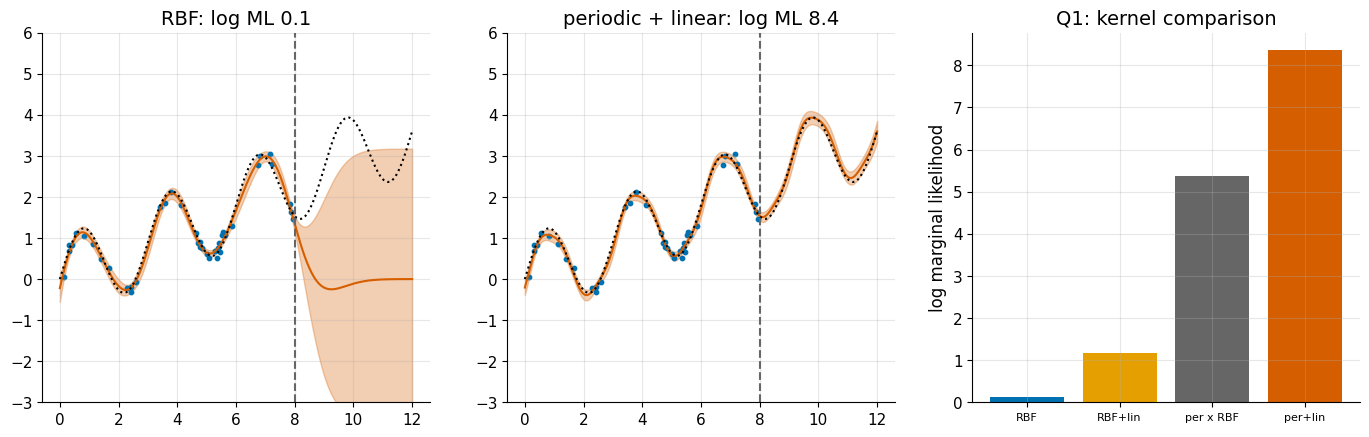

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8)); xe_all = np.linspace(0, 12, 300)[:, None]
for ax, nm in zip(axes[:2], ("RBF", "periodic + linear")):
    mk_, st, npar = specs[nm]; best = None
    for s0 in st:
        for sn0 in (0.1, 0.3):
            r = minimize(lambda p: -lml(Xk, yk, mk_(p[:npar]), np.exp(p[npar])), np.r_[np.log(s0), np.log(sn0)], method="L-BFGS-B", bounds=[(-5, 5)] * (npar + 1))
            if best is None or r.fun < best.fun: best = r
    m_, v_ = gp_post(Xk, yk, xe_all, mk_(best.x[:npar]), np.exp(best.x[npar])); s_ = np.sqrt(v_); ax.fill_between(xe_all[:, 0], m_ - 1.96 * s_, m_ + 1.96 * s_, color=HIGHLIGHT, alpha=0.3); ax.plot(xe_all[:, 0], m_, color=HIGHLIGHT); ax.plot(xe_all[:, 0], ftr(xe_all[:, 0]), "k:"); ax.scatter(Xk[:, 0], yk, s=10, color=MAIN); ax.axvline(8, color=NEUTRAL, linestyle="--"); ax.set_ylim(-3, 6); ax.set_title(f"{nm}: log ML {tb3.loc[nm, 'log marginal likelihood']:.1f}")
axes[2].bar(range(4), tb3["log marginal likelihood"], color=[MAIN, SIM, NEUTRAL, HIGHLIGHT]); axes[2].set_xticks(range(4)); axes[2].set_xticklabels(["RBF", "RBF+lin", "per x RBF", "per+lin"], fontsize=8); axes[2].set_ylabel("log marginal likelihood"); axes[2].set_title("Q1: kernel comparison")
plt.show()

### 12.9 Interpretation and decision (Example 3)
- The maximised log marginal likelihood is **0.12** for the RBF kernel, 1.18 for RBF + linear, 5.36 for periodic $\times$ RBF and **8.36 for periodic + linear**: the kernel that encodes the true structure (a repeating pattern plus a trend) wins by a wide margin.
- **It is also the best extrapolator:** RMSE on $[8,12]$ of **0.093** (periodic + linear), 0.491 (periodic $\times$ RBF), 0.916 (RBF + linear) and **2.96 (RBF)**, which reverts to the prior mean outside the data. The predictive SDs tell the same story: 0.088 for the winning kernel (close to its RMSE, so it is well calibrated), but only 1.30 for the RBF whose RMSE is 2.96 and 0.33 for periodic $\times$ RBF whose RMSE is 0.49: a wrong kernel is over-confident.
- **Decision.** Compare kernels by their marginal likelihood before trusting an extrapolation, and build known structure (trend, seasonality) into the kernel instead of expecting a stationary RBF to extrapolate.

---
### Example 4: kriging a temperature map with leave-one-out validation

**Scenario.** The 40 weather stations of 9.3 measure a smooth temperature field with noise SD 0.5. We fit a GP (RBF, hyperparameters by marginal likelihood) and (a) predict the field at 2,000 unobserved locations, (b) compute leave-one-out predictions at the stations (closed form from the inverse kernel matrix), and (c) compare with inverse-distance weighting (power 2).

**Questions.** (1) Fitted hyperparameters and the RMSE of the map against the true field. (2) Leave-one-out RMSE and coverage of the GP against inverse-distance weighting. (3) Where is the map most uncertain?

In [22]:
thK, llK = (lambda r: (np.exp(r.x), -r.fun))(minimize(lambda p: -lml(S, T_ - mu_t, lambda A, B: rbf(A, B, np.exp(p[0]), np.exp(p[1])), np.exp(p[2])), np.log([2.5, 4.0, 0.5]), method="L-BFGS-B", bounds=[(-3, 4)] * 3)); kK = lambda A, B: rbf(A, B, thK[0], thK[1]); g = np.random.default_rng(41); Pt = g.uniform(0, 10, (2000, 2)); mP, vP = gp_post(S, T_ - mu_t, Pt, kK, thK[2]); mP = mP + mu_t
Kinv = np.linalg.inv(kK(S, S) + thK[2] ** 2 * np.eye(40)); yc = T_ - mu_t; loo_m = yc - (Kinv @ yc) / np.diag(Kinv); loo_s = np.sqrt(1 / np.diag(Kinv)); loo_m = loo_m + mu_t
def idw(Q, S_, y_, p=2): d = np.linalg.norm(Q[:, None] - S_[None], axis=2) + 1e-9; w = d ** -p; return (w * y_[None]).sum(axis=1) / w.sum(axis=1)
idw_loo = np.array([idw(S[i:i + 1], np.delete(S, i, 0), np.delete(T_, i)) [0] for i in range(40)]); idw_map = idw(Pt, S, T_)
print(f"Q1: hyperparameters: length scale {thK[0]:.2f}, signal SD {thK[1]:.2f}, noise SD {thK[2]:.3f} (true 0.5); RMSE of the map against the true field: GP {np.sqrt(np.mean((mP - field(Pt)) ** 2)):.4f}, IDW {np.sqrt(np.mean((idw_map - field(Pt)) ** 2)):.4f}")
cov_loo = np.mean(np.abs(T_ - loo_m) < 1.96 * np.sqrt(loo_s ** 2)); print(f"Q2: leave-one-out RMSE (against the noisy readings): GP {np.sqrt(np.mean((T_ - loo_m) ** 2)):.4f}, IDW {np.sqrt(np.mean((T_ - idw_loo) ** 2)):.4f} | LOO coverage of the 95% interval {cov_loo:.3f} | closed-form LOO equals the explicit refit: {np.abs(loo_m[3] - (gp_post(np.delete(S, 3, 0), np.delete(T_ - mu_t, 3), S[3:4], kK, thK[2])[0][0] + mu_t)).max():.2e} difference")
print(f"Q3: posterior SD of the map: mean {np.sqrt(vP).mean():.3f}, maximum {np.sqrt(vP).max():.3f} at {Pt[np.argmax(vP)].round(2)}; mean SD for points farther than 2 units from any station: {np.sqrt(vP)[np.min(np.linalg.norm(Pt[:, None] - S[None], axis=2), axis=1) > 2].mean():.3f}")

Q1: hyperparameters: length scale 3.91, signal SD 3.69, noise SD 0.453 (true 0.5); RMSE of the map against the true field: GP 0.3155, IDW 1.1252
Q2: leave-one-out RMSE (against the noisy readings): GP 0.6030, IDW 1.2392 | LOO coverage of the 95% interval 1.000 | closed-form LOO equals the explicit refit: 4.81e-10 difference
Q3: posterior SD of the map: mean 0.327, maximum 1.446 at [0.   0.08]; mean SD for points farther than 2 units from any station: 1.073


### 12.7 Asserts

In [23]:
assert np.sqrt(np.mean((mP - field(Pt)) ** 2)) < np.sqrt(np.mean((idw_map - field(Pt)) ** 2)) and np.sqrt(np.mean((T_ - loo_m) ** 2)) < np.sqrt(np.mean((T_ - idw_loo) ** 2)) and abs(thK[2] - 0.5) < 0.3 and 0.8 < cov_loo <= 1.0
assert np.abs(loo_m[3] - (gp_post(np.delete(S, 3, 0), np.delete(T_ - mu_t, 3), S[3:4], kK, thK[2])[0][0] + mu_t)).max() < 1e-6
print("all checks passed")

all checks passed


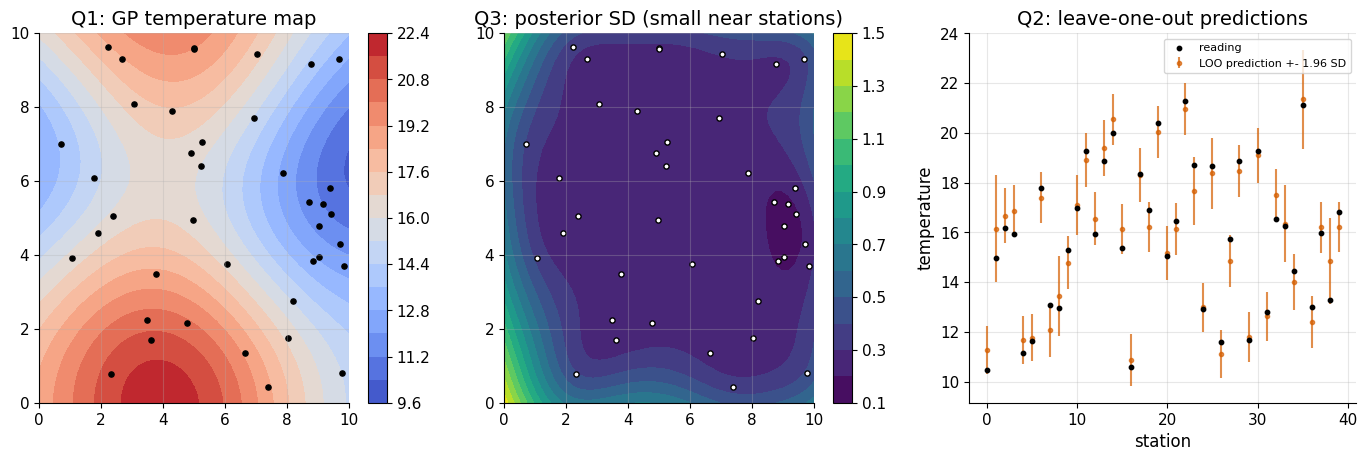

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8)); gxx, gyy = np.meshgrid(np.linspace(0, 10, 50), np.linspace(0, 10, 50)); PP = np.column_stack([gxx.ravel(), gyy.ravel()]); mG, vG = gp_post(S, T_ - mu_t, PP, kK, thK[2]); im = axes[0].contourf(gxx, gyy, (mG + mu_t).reshape(gxx.shape), 15, cmap="coolwarm"); axes[0].scatter(S[:, 0], S[:, 1], c="black", s=14); axes[0].set_title("Q1: GP temperature map"); plt.colorbar(im, ax=axes[0])
im = axes[1].contourf(gxx, gyy, np.sqrt(vG).reshape(gxx.shape), 15, cmap="viridis"); axes[1].scatter(S[:, 0], S[:, 1], c="white", s=14, edgecolors="black"); axes[1].set_title("Q3: posterior SD (small near stations)"); plt.colorbar(im, ax=axes[1])
axes[2].errorbar(np.arange(40), loo_m, yerr=1.96 * loo_s, fmt="o", color=HIGHLIGHT, markersize=3, alpha=0.7, label="LOO prediction +- 1.96 SD"); axes[2].scatter(np.arange(40), T_, color="black", s=10, label="reading", zorder=3); axes[2].legend(fontsize=8); axes[2].set_xlabel("station"); axes[2].set_ylabel("temperature"); axes[2].set_title("Q2: leave-one-out predictions")
plt.show()

### 12.11 Interpretation and decision (Example 4)
- The learned hyperparameters are a length scale of **3.91**, a signal SD of 3.69 and a noise SD of **0.453** (true 0.5). The map of the temperature field has an RMSE of **0.316** against the true field, against **1.125** for inverse-distance weighting (3.6 times worse).
- Leave-one-out validation at the 40 stations: GP RMSE **0.603** (about the noise level 0.5 plus the interpolation error) against **1.239** for inverse-distance weighting; the 95 % intervals cover 100 % of the readings. The closed-form leave-one-out formula equals the explicit refit to $5\times10^{-10}$, so no refitting is needed.
- **The map is most uncertain in the corners:** the posterior SD averages 0.327 over the map, but 1.073 at points more than 2 units from any station and reaches 1.446 near the corner (0, 0.08); at a station it is 0.41, close to the noise level.
- **Decision.** Use kriging (GP regression) for spatial interpolation and put new stations where the posterior SD is largest (the same idea as expected improvement in Example 2).

## 13. Where it is used

### Statistics
- **Kriging in geostatistics**, spatial and spatio-temporal modelling, **nonparametric Bayesian regression and classification**, smoothing splines as GP posterior means, **emulators of computer experiments**, functional data analysis.

### Data science
- **Interpolation with honest error bars** for sensors and surveys, **Bayesian optimisation** of hyperparameters and experiments (A/B designs, formulations, simulation tuning), **active learning**, forecasting with seasonality (periodic kernels), calibrated uncertainty on small data.

### ML and AI
- **Hyperparameter tuning** (BoTorch, Optuna's GP sampler), **surrogate models** inside reinforcement learning and robotics, **infinite-width neural networks are GPs** (NNGP and the neural tangent kernel), **neural processes** and meta-learning priors over functions, safe exploration, and the uncertainty baseline against which deep ensembles (09_06) are compared.

## 14. Common pitfalls and misconceptions

- **Using default hyperparameters:** the length scale decides everything (8.3); fit it by marginal likelihood or validation.
- **Trusting intervals when the kernel is wrong:** a smooth RBF kernel on rough data gives confident, wrong bands (Example 3); check the standardised residuals and the leave-one-out coverage.
- **Mixing up the two intervals:** the band for the *function* excludes the observation noise; the band for *new observations* adds $\sigma_n^2$.
- **Scaling to large $n$:** the $O(n^3)$ cost makes exact GPs impractical beyond a few thousand points; use sparse or approximate GPs.
- **Forgetting the mean:** with a zero-mean prior the predictions revert to 0 far from the data; subtract the sample mean or add a mean function.
- **Poorly identified hyperparameters:** with few data the length scale and the noise can trade off; look at the likelihood surface (9.1) and use priors on the hyperparameters.
- **Over-reading EI:** Bayesian optimisation assumes a smooth objective and a good surrogate; it can stall when the first points mislead the model (Example 2).
- **Extrapolating with stationary kernels:** an RBF GP reverts to the prior mean outside the data; encode trend or periodicity in the kernel if you must extrapolate.

## 15. Exercises

1. Compute the RBF kernel correlations $k(0,d)/\sigma_f^2$ for $d=0.5,1,2,3$ and $\ell=1$, and the distance at which the correlation drops to 0.05.
2. Two observations $y=(1.0,1.2)$ at $x=(0,0.5)$ with noise SD 0.1, RBF kernel $\ell=1,\sigma_f=1$: compute the posterior mean and SD at $x=0.25$ by hand and with the code.
3. Verify numerically that the posterior variance does not depend on the observed values $y$.
4. Fit a GP with a Matern 3/2 kernel to the sensor data of Example 1 and compare the log marginal likelihood and RMSE with the RBF.
5. For the function $g$ of Example 2, run EI with 25 evaluations and report the best value and the evaluated points.
6. (Harder) Implement the lower confidence bound $\mu-2s$ acquisition instead of EI for Example 2 and compare with EI over 60 runs.

Solutions are at the end.

## 16. Summary table

| Item | Formula | Note |
|---|---|---|
| GP | $f\sim\mathcal{GP}(m,k)$ | distribution over functions |
| Posterior mean | $k_*^\top(K+\sigma_n^2I)^{-1}y$ | linear in $y$ |
| Posterior variance | $k_{**}-k_*^\top(K+\sigma_n^2I)^{-1}k_*$ | independent of $y$ |
| Log marginal likelihood | $-\frac12y^\top K_y^{-1}y-\frac12\ln|K_y|-\frac n2\ln2\pi$ | fit + complexity |
| RBF kernel | $\sigma_f^2e^{-r^2/2\ell^2}$ | smooth functions |
| Expected improvement | $(f_{\min}-\mu)\Phi(z)+s\varphi(z)$ | Bayesian optimisation |
| Cost | $O(n^3)$ | up to a few thousand points |
| tools | Cholesky solves, `scipy.optimize` | |

## Solutions

In [25]:
d = np.array([0.5, 1, 2, 3]); print("1: correlations", np.exp(-d ** 2 / 2).round(4), "| correlation 0.05 at d =", round(float(np.sqrt(-2 * np.log(0.05))), 4), "lengths")
X2 = np.array([[0.0], [0.5]]); y2 = np.array([1.0, 1.2]); m2_, v2_ = gp_post(X2, y2, np.array([[0.25]]), lambda A, B: rbf(A, B, 1, 1), 0.1); K_ = rbf(X2, X2, 1, 1) + 0.01 * np.eye(2); ks = rbf(np.array([[0.25]]), X2, 1, 1)[0]; print(f"2: mean {m2_[0]:.4f}, SD {np.sqrt(v2_[0]):.4f} | by hand: mean {ks @ np.linalg.solve(K_, y2):.4f}, variance {1 - ks @ np.linalg.solve(K_, ks):.4f}")
v_a = gp_post(Xk, yk, Xe, lambda A, B: rbf(A, B, 1.0, 1.0), 0.15)[1]; v_b = gp_post(Xk, yk + 10 * np.random.default_rng(1).normal(size=40), Xe, lambda A, B: rbf(A, B, 1.0, 1.0), 0.15)[1]; print("3: largest difference of the posterior variance for two different y:", np.abs(v_a - v_b).max())
m32 = lambda p: (lambda A, B: matern32(A, B, np.exp(p[0]), np.exp(p[1]))); rM = minimize(lambda p: -lml(X1, y1 - mu1, m32(p[:2]), np.exp(p[2])), np.log([2.0, 3.0, 0.4]), method="L-BFGS-B", bounds=[(-4, 4)] * 3); mM, _ = gp_post(X1, y1 - mu1, Xq, m32(rM.x[:2]), np.exp(rM.x[2])); print(f"4: Matern 3/2: log ML {-rM.fun:.3f} vs RBF {ll1:.3f}; RMSE on the missing readings {np.sqrt(np.mean((mM[miss] + mu1 - truth[miss]) ** 2)):.4f} vs RBF {rm(m1):.4f}")
b25, X25 = bo(3, n_total=25); print(f"5: EI with 25 evaluations (seed 3): best value {b25[-1]:.4f} (global {gm:.4f}); evaluated points (sorted) {np.sort(X25).round(2).tolist()}")
def bo_lcb(seed, n_total=15):
    g = np.random.default_rng(seed); X = list(g.uniform(0, 10, 3)); y = [gfun(x) + 0.05 * g.normal() for x in X]; cand = np.linspace(0, 10, 400)[:, None]
    while len(X) < n_total:
        ym = np.array(y); mu_ = ym.mean(); th, _ = fit_rbf(np.array(X)[:, None], ym - mu_, starts=((1.0, 1.0, 0.1), (2.0, 1.0, 0.1))); m_, v_ = gp_post(np.array(X)[:, None], ym - mu_, cand, lambda A, B: rbf(A, B, th[0], th[1]), th[2]); xn = cand[np.argmin(m_ + mu_ - 2 * np.sqrt(v_)), 0]; X.append(xn); y.append(gfun(xn) + 0.05 * g.normal())
    return gfun(np.array(X)).min()
lcb = np.array([bo_lcb(s) for s in range(40)]); print(f"6: LCB over 40 runs: mean best value {lcb.mean():.4f}, share within 0.05 of the minimum {np.mean(lcb < gm + 0.05):.2f} | EI (60 runs): {B_bo[:, -1].mean():.4f}, {np.mean(B_bo[:, -1] < gm + 0.05):.2f}")
assert np.abs(v_a - v_b).max() < 1e-9 and abs(m2_[0] - ks @ np.linalg.solve(K_, y2)) < 1e-9

1: correlations [0.8825 0.6065 0.1353 0.0111] | correlation 0.05 at d = 2.4477 lengths
2: mean 1.1267, SD 0.0850 | by hand: mean 1.1267, variance 0.0072
3: largest difference of the posterior variance for two different y: 0.0
4: Matern 3/2: log ML -64.215 vs RBF -63.397; RMSE on the missing readings 0.1544 vs RBF 0.1118


5: EI with 25 evaluations (seed 3): best value -1.0326 (global -1.0347); evaluated points (sorted) [0.0, 0.86, 2.37, 3.41, 4.39, 5.64, 7.22, 7.24, 7.24, 7.29, 7.29, 7.39, 7.39, 7.39, 7.39, 7.39, 7.42, 7.42, 7.42, 7.42, 7.42, 7.44, 7.77, 8.01, 10.0]


6: LCB over 40 runs: mean best value -1.0169, share within 0.05 of the minimum 0.90 | EI (60 runs): -1.0290, 1.00


**1.** The correlations $e^{-d^2/2}$ are **0.883, 0.607, 0.135 and 0.011** for $d=0.5,1,2,3$; the correlation drops to 0.05 at $d=\sqrt{-2\ln0.05}=$ **2.45** length scales.

**2.** The posterior mean at $x=0.25$ is **1.1267** and the SD **0.0850** (variance 0.0072); the explicit formula $k_*^\top K_y^{-1}y$ gives the same values.

**3.** The largest difference between the posterior variances for two completely different sets of observed values is **0.0**: the variance depends only on where the data were taken.

**4.** The Matern 3/2 kernel gives a log marginal likelihood of **-64.2** against **-63.4** for the RBF and an RMSE on the missing readings of **0.154** against **0.112**: for this very smooth sensor signal the smoother kernel is slightly better, as the marginal likelihood says.

**5.** With 25 evaluations (seed 3) EI reaches **-1.0326** (global minimum -1.0347); 15 of the 25 points lie between 7.22 and 7.44, around the minimiser at 7.365.

**6.** The lower-confidence-bound rule gives a mean best value of **-1.0169** and finds a value within 0.05 of the minimum in **90 %** of 40 runs, against **-1.0290** and 100 % for EI over 60 runs.